# MATH 60231 – Homework #3
**Group:** Mathis Huot, Nathan Madore, Isabelle Tanara

Due: Monday, November 23, 2026

# Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from numpy.random import default_rng, PCG64
from scipy import stats

## Table formatting function 

Source used for Table Formatting: [MatPlotLib - Table Demo](https://matplotlib.org/stable/gallery/misc/table_demo.html)

In [2]:
# Table formatting template (Sourced from MatPlotLib, linked above)
import os, re
os.makedirs("Output", exist_ok=True)                       # every table and figure is also saved as a PNG in Output/

def save_output(fig, label):
    """Save a matplotlib figure as a PNG in the Output/ folder.

    Parameters
    ----------
    fig : matplotlib.figure.Figure
        Figure to save.
    label : str
        Table/figure title; turned into a safe file name
        (e.g. "Table 2.4 - AR models" -> "Output/Table_2.4_AR_models.png").
    """
    # File name built from the label: "Table 2.4 – AR models ..." -> Output/Table_2.4_AR_models_....png
    name = re.sub(r"[^A-Za-z0-9.]+", "_", label).strip("_.")[:90]
    
    fig.savefig(f"Output/{name}.png", dpi=200, bbox_inches="tight")


def table_figure(df, title, row_labels=None, decimals=6, col_colors=None, figsize=(12, 2.2)):
    """Render a DataFrame as a table image, save it to Output/ and display it.

    Parameters
    ----------
    df : pd.DataFrame
        Numbers to show (NaN cells are printed as "-").
    title : str
        Title above the table; also used as the file name.
    row_labels : list, optional
        Row labels to use instead of df.index.
    decimals : int
        Number of decimals shown in each cell.
    col_colors : list, optional
        Background colour of each column header.
    figsize : tuple
        Figure size in inches.
    """
    cell_text = []
    
    for row in df.values:
        row_text = []
        
        for x in row:
            if pd.notna(x):
                row_text.append(f"{x:,.{decimals}f}")      # number with thousands separator
            else:
                row_text.append("-")                       # "-" for empty cells
        
        cell_text.append(row_text)
    
    if row_labels is None:
        row_labels = list(df.index.astype(str))
    else:
        row_labels = list(row_labels)

    fig, ax = plt.subplots(figsize=figsize)
    ax.axis("off")
    table = ax.table(cellText=cell_text,
                     rowLabels=row_labels,
                     colLabels=list(df.columns),
                     colColours=col_colors,
                     loc="center",
                     cellLoc="center",
                     rowLoc="center")
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1, 1.4)
    ax.set_title(title, pad=20)
    plt.tight_layout()
    save_output(fig, title)                                 # save to Output/ before displaying
    plt.show()

## Data loading

In [3]:
# Problem 1: hourly PJM, Zonal COMED price only
PJM_data = pd.read_csv('Data/PJM.csv', skipinitialspace=True, parse_dates=['Date'], index_col='Date')
PJM_data.columns = ["price", "S_load", "Z_load"]
price_h = PJM_data['price'].iloc[-8760:]               # last 8,760 hours = calendar year 2018
price_d = PJM_data['price'].resample('D').mean()       # daily average, as in HW2 (only used in 1e)

# Problem 2 (a)-(e): daily UK gilt yields, 15 maturities
gilts = pd.read_parquet('Data/UK_bonds.parquet')

# Problem 2 (d), (f): S&P 500, oldest first, in logs
spx = pd.read_csv('Data/S&P 500 Historical Data.csv', thousands=',',
                  parse_dates=['Date'], index_col='Date').sort_index()
log_spx = np.log(spx['Price'])

print(price_h.index[[0, -1]], gilts.shape, log_spx.index[[0, -1]])

DatetimeIndex(['2017-12-25 00:00:00', '2018-12-24 23:00:00'],
              dtype='datetime64[us]', name='Date', freq=None) (1114, 15) DatetimeIndex(['2002-01-02', '2021-11-09'], dtype='datetime64[us]', name='Date',
              freq=None)


# Problem 1 – Simulating Forecast Uncertainty [40 pts]
Hourly PJM data, `price` (Zonal COMED) only, last 8,760 hourly observations (2018). Do **not** aggregate to daily (except in 1e).

## 1a. `Q1_ARForecast()` [5 pts]
Function taking a p×1 array `s` (most recent p obs) and a (1+p)×1 array `phi`; returns the 1-step-ahead forecast ŝ(t+1) = φ0 + Σ φj·s(t−j+1). Apply with an AR(24) estimated on 2018 hourly prices.

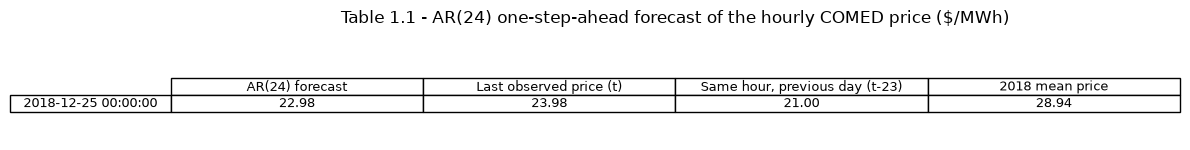

In [4]:
def Q1_ARForecast(s, phi):
    s = np.array(s, dtype=float).ravel()  # ensure s is a 1D array
    phi = np.asarray(phi, dtype=float).ravel()
    p = len(phi)-1 # AR order is one less than the length of phi

    # Safety check (SIZE OF INPUTS)
    if len(s) != p:                                    
        raise ValueError(f"s has {len(s)} observations but phi implies p = {p}")

    # Forecast formula
    return float(phi[0] + phi[1:] @ s[::-1])


# Estimating AR(24)
p = 24
phi_24 = AutoReg(price_h.values, lags=p).fit().params

# 1-step-ahead forecast from the last 24 hours of 2018
fc_1a = Q1_ARForecast(price_h.values[-p:], phi_24)
target = price_h.index[-1] + pd.Timedelta(hours=1)

# Values to compare the forecast with, in the write-up
table_1a = pd.DataFrame({
    'AR(24) forecast': [fc_1a],
    'Last observed price (t)': [price_h.iloc[-1]],
    'Same hour, previous day (t-23)': [price_h.iloc[-24]],
    '2018 mean price': [price_h.mean()],
}, index=[str(target)])

table_figure(table_1a, f"Table 1.1 - AR(24) one-step-ahead forecast of the hourly COMED price ($/MWh)",
             decimals=2, figsize=(12, 1.6))


## 1b. `Q1_AREstimate()` [10 pts]
Function taking a T×1 array `s` and integer `p`; returns the (1+p)×1 coefficients `phi` and the (T−p)×1 in-sample residuals. Apply with p = 24; report coefficients and plot the residual ACF.


Max |our phi - statsmodels phi| = 1.3766765505351941e-14


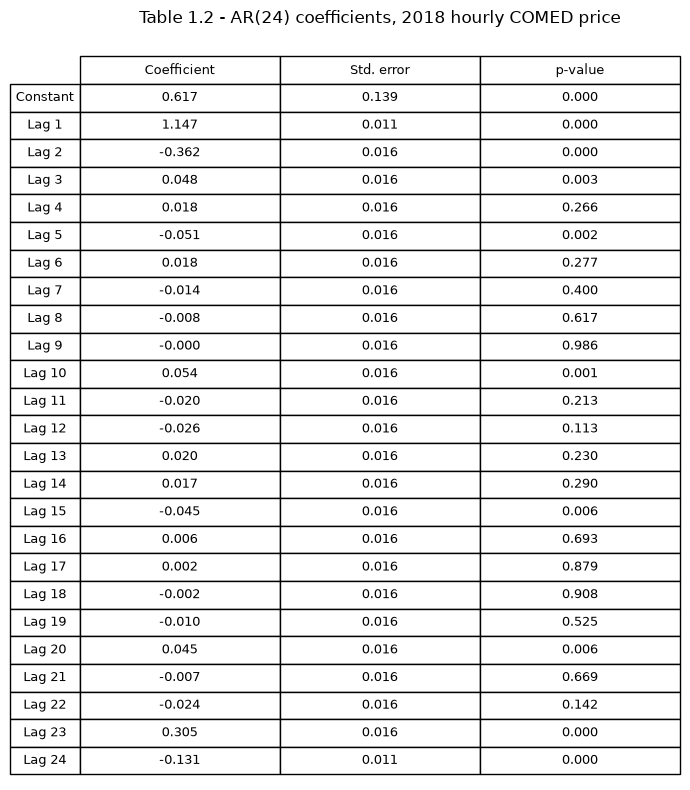

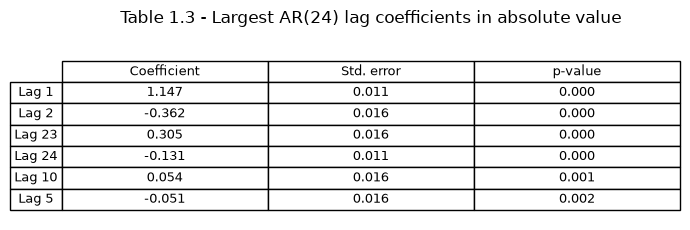

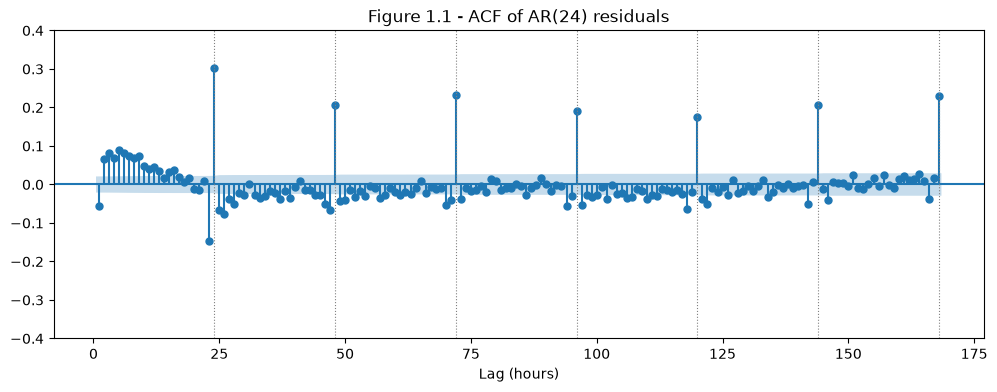

In [8]:
def Q1_AREstimate(s, p):
    """Estimate an AR(p) model by OLS.

    Regresses s_t on a constant and its p lags: s_t = phi_0 + sum_j phi_j * s_{t-j} + e_t.

    Parameters
    ----------
    s : array-like, shape (T,)
        The series [s_1, ..., s_T], oldest to newest.
    p : int
        AR order (number of lags).

    Returns
    -------
    phi : np.ndarray, shape (1 + p,)
        Estimated coefficients [phi_0, phi_1, ..., phi_p].
    resid : np.ndarray, shape (T - p,)
        In-sample residuals e_hat_t = s_t - s_hat_t, for t = p+1, ..., T.
    """
    s = np.asarray(s, dtype=float).ravel()  
    T = len(s)
    y = s[p:]                                          # target value being explained

    # Regressor matrix
    X = np.column_stack([np.ones(T - p)] + [s[p - j:T - j] for j in range(1, p + 1)])
    phi = np.linalg.lstsq(X, y, rcond=None)[0]         # phi (OLS) = (X'X)^-1 X'y 
    resid = y - X @ phi                                # Residuals

    return phi, resid


# Apply to hourly price with lags = 24
p = 24
phi_24, resid_24 = Q1_AREstimate(price_h.values, p)

# Gives standard errors and p-values for the table (and cross-validates with statsmodels)
ar_24 = AutoReg(price_h.values, lags=p).fit()
print("Max |our phi - statsmodels phi| =", np.abs(phi_24 - ar_24.params).max())

# (i) Coefficient table
coef_1b = pd.DataFrame({'Coefficient': phi_24,
                        'Std. error': ar_24.bse,
                        'p-value': ar_24.pvalues},
                       index=['Constant'] + [f'Lag {j}' for j in range(1, p + 1)])

# Calling table formatting
table_figure(coef_1b, "Table 1.2 - AR(24) coefficients, 2018 hourly COMED price",
             decimals=3, figsize=(7, 8))

# (i) Lags ranked by absolute size  
lags_1b = coef_1b.iloc[1:]
top_1b = lags_1b.loc[lags_1b['Coefficient'].abs().sort_values(ascending=False).index].head(6)

# Calling table formatting
table_figure(top_1b, "Table 1.3 - Largest AR(24) lag coefficients in absolute value",
             decimals=3, figsize=(7, 2.4))

# (ii) Build figure for ACF of the residuals over 168 hours
fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(resid_24, lags=168, ax=ax, zero=False)
for k in range(24, 169, 24):                           # Lines at multiples of 24 h
    ax.axvline(k, color='grey', ls=':', lw=0.8)
ax.set_xlabel('Lag (hours)')
ax.set_ylim(-0.4, 0.4)
ax.set_title('Figure 1.1 - ACF of AR(24) residuals')
save_output(fig, "Figure 1.1 - ACF of AR(24) residuals")
plt.show()


## 1c. `Q1_SimPath()` [10 pts]
Function taking a BitGenerator `bg`, `s` (last p obs), `phi`, residuals `e` and horizon `h`; returns one simulated path of length h (AR recursion + bootstrapped residuals). Apply with h = 48; plot 3 paths with the last 72 in-sample hours and a vertical separator.

## 1d. `Q1_SimBands()` [10 pts]
Function taking `bg`, `s`, and integers `p`, `h`, `N`; returns an N×h array of paths by calling `Q1_SimPath()` N times (same `phi` and residuals). Apply with p = 24, h = 48, N = 1,000; plot 5th/95th percentiles with the point forecast.

## 1e. DM test: hourly AR(24) vs daily AR(6) [5 pts]
Average the hourly AR(24) 1-step-ahead rolling forecasts within each day, then compare with the HW2 daily AR(6) forecasts using `Q2_DM()`. Report the DM statistic and p-value.

### HW2 carry-over (same as Homework 2)
Functions and daily AR(6) forecasts copied unchanged from Homework 2, Problem 2 (d)–(e).

In [6]:
# ---- Carried over from Homework 2 (unchanged): Q2_RollForecast, Q2_Realised, Q2_DM ----
def Q2_RollForecast(s, T0, p, h):
    """Rolling fixed-window AR(p) forecasts.

    For each window of T0 consecutive observations, re-estimate AR(p) on that
    window only and forecast the next h days. The window then moves forward
    by one day.

    Parameters
    ----------
    s : array-like
        The series (daily COMED price).
    T0 : int
        Window length (number of observations used in each estimation).
    p : int
        AR order.
    h : int
        Maximum forecast horizon.

    Returns
    -------
    np.ndarray
        Shape (n_windows, h): row i = forecasts for h = 1..h from window i.
    """
    s = np.asarray(s, dtype=float)
    n_windows = len(s) - T0 - h + 1                  # last window still has h realised values after it
    forecasts = np.empty((n_windows, h))
    
    # Loop over all windows, re-estimate AR(p) on each window, and forecast h steps ahead
    for i in range(n_windows):
        window = s[i:i + T0]                         
        res = AutoReg(window, lags=p).fit()          # re-estimate AR(p) on this window only
        forecasts[i] = res.forecast(h)               
    
    return forecasts


def Q2_Realised(s, T0, h):
    """Actual values matching the forecasts of Q2_RollForecast().

    Parameters
    ----------
    s : array-like
        The series (daily COMED price).
    T0 : int
        Window length (same as in Q2_RollForecast()).
    h : int
        Maximum forecast horizon.

    Returns
    -------
    np.ndarray
        Shape (n_windows, h): row i = the h values observed right after window i.
        Forecast errors are then realised - forecasts.
    """
    s = np.asarray(s, dtype=float)
    n_windows = len(s) - T0 - h + 1
    realised = []
    
    for i in range(n_windows):                       # the h values right after window i
        realised.append(s[i + T0:i + T0 + h])
    
    return np.array(realised)


def Q2_DM(d, h):
    """Diebold-Mariano statistic for H0: E[d] = 0.

    The statistic is mean(d) divided by its standard error. The variance uses
    a Newey-West (Bartlett-weighted) long-run variance with h - 1
    autocovariances, because h-step forecast errors overlap.

    Parameters
    ----------
    d : array-like
        Loss differential, one value per forecast.
        Equal MSFE (2e): d = e_AR3^2 - e_AR6^2.
        Encompassing (2f): d = e_AR3 * (e_AR3 - e_AR6).
    h : int
        Forecast horizon.

    Returns
    -------
    float
        DM statistic, approximately N(0, 1) under H0.
    """
    d = np.asarray(d, dtype=float)
    T = len(d)
    u = d - d.mean()
    lrv = u @ u / T                                      
    
    for k in range(1, h):                                # h-1 autocovariances (MA(h-1) under H0)
        lrv += 2 * (1 - k / h) * (u[k:] @ u[:-k]) / T    # Bartlett weighted variance (keeps it positive)
    
    return d.mean() / np.sqrt(lrv / T)                   # ~ N(0,1) under H0: E[d] = 0


# HW2 daily AR(6) rolling forecasts (same settings as HW2: T0 = 300, h = 24)
T0, h = 300, 24
forecast_ar6 = Q2_RollForecast(price_d, T0, 6, h)

# 1-step-ahead AR(6) daily forecasts, indexed by the day being forecast
ar6_1step = pd.Series(forecast_ar6[:, 0], index=price_d.index[T0:T0 + len(forecast_ar6)])
print(ar6_1step.tail())

Date
2018-11-27    31.361982
2018-11-28    34.304263
2018-11-29    37.460548
2018-11-30    33.055005
2018-12-01    33.439457
Freq: D, dtype: float64


# Problem 2 – Unit Roots & Cointegration [50 pts]
Parts (a)–(e): `UK_bonds.parquet` (daily gilt yields, 15 maturities). Parts (d), (f): `S&P 500 Historical Data.csv` (log index).

## 2a. Descriptive statistics & graphs [5 pts]
Descriptive statistics for all maturities; one labelled time-series plot (2Yr, 5Yr, 10Yr, 40Yr); mean yield curve across maturities.

## 2b. `Q2_ADF()` [10 pts]
Function taking a Series `s` and integer `p`; returns (i) ADF t-stat, constant; (ii) ADF t-stat, constant + trend; (iii) δ = T·β̂, constant; (iv) δ, constant + trend. Apply to 2Yr and 10Yr with p = 5.

## 2c. `Q2_CVSim()` [10 pts]
Function taking a Series `s` and integers `N`, `T`, `p`; returns a 3×4 DataFrame of 90/95/99% critical values for the four statistics, from N bootstrapped random walks (increments drawn from Δs). Apply to 10Yr with p = 5, T = 400, N = 500.

## 2d. Bootstrap critical values for the log S&P 500 [10 pts]
`Q2_CVSim()` on the last 400 obs of the log S&P 500 with p = 3, T = 400, N = 500. Compare with 2c, then apply `Q2_ADF()` (last 400 obs, p = 3).

## 2e. `Q2_RollingADF()` [10 pts]
Function taking a Series `s` and integers `p`, `N < len(s)`; runs `Q2_ADF()` on every rolling window of N obs. Returns a 3×4 DataFrame: most negative value, window start date, window end date. Apply to 10Yr with p = 5, N = 250.

## 2f. Rolling ADF on the log S&P 500 [5 pts]
`Q2_RollingADF()` on the last 1,500 obs of the log S&P 500 with p = 3, N = 250.